In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("C:\\Users\\saqli\\Downloads\\workspace\\Employee-Attrition-Project\\data\\employee_attrition_clean.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (1000, 8)
   EmployeeID  TotalMonthsOfExp  TotalOrgsWorked  MonthsInOrg  \
0           1               110                4            9   
1           2               103                3           51   
2           3                41                4           16   
3           4                32                4           17   
4           5                80                3           16   

   LastPayIncrementBand  AverageFeedback  LastPromotionYears  Attrition  
0                     5                4                   4          1  
1                     1                4                   2          0  
2                     5                4                   4          1  
3                     5                2                   3          0  
4                     3                4                   2          0  


In [3]:
features = [
    "TotalMonthsOfExp",
    "TotalOrgsWorked",
    "MonthsInOrg",
    "LastPayIncrementBand",
    "AverageFeedback"
]

X = df[features].copy()

print(X.head())
print("\nMissing values:")
print(X.isnull().sum())

   TotalMonthsOfExp  TotalOrgsWorked  MonthsInOrg  LastPayIncrementBand  \
0               110                4            9                     5   
1               103                3           51                     1   
2                41                4           16                     5   
3                32                4           17                     5   
4                80                3           16                     3   

   AverageFeedback  
0                4  
1                4  
2                4  
3                2  
4                4  

Missing values:
TotalMonthsOfExp        0
TotalOrgsWorked         0
MonthsInOrg             0
LastPayIncrementBand    0
AverageFeedback         0
dtype: int64


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed.
Scaled data shape: (1000, 5)


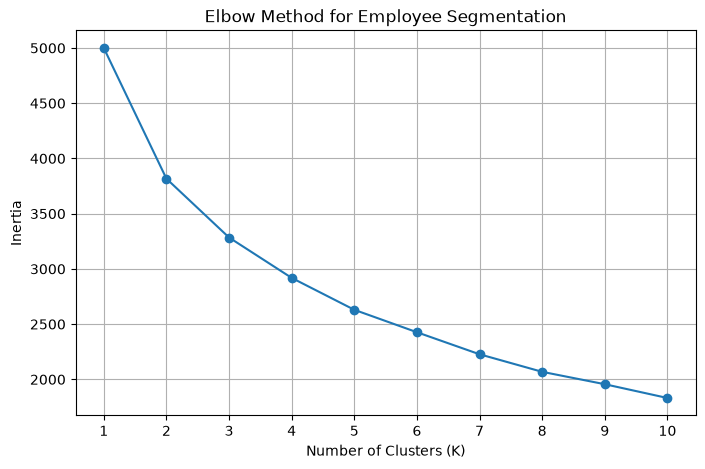

In [5]:
inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Employee Segmentation")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [6]:
k = 3  # Change this based on your Elbow Method plot

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["EmployeeID", "Cluster"]].head(10))
print("\nEmployees in each cluster:")
print(df["Cluster"].value_counts().sort_index())

   EmployeeID  Cluster
0           1        2
1           2        1
2           3        2
3           4        0
4           5        2
5           6        1
6           7        0
7           8        2
8           9        2
9          10        1

Employees in each cluster:
Cluster
0    345
1    287
2    368
Name: count, dtype: int64


In [7]:
cluster_summary = df.groupby("Cluster")[features].mean().round(2)

print("Cluster Characteristics:")
print(cluster_summary)

Cluster Characteristics:
         TotalMonthsOfExp  TotalOrgsWorked  MonthsInOrg  LastPayIncrementBand  \
Cluster                                                                         
0                   48.49             3.06        17.72                  3.21   
1                   97.54             3.03        64.65                  2.86   
2                   44.24             3.07        17.21                  3.08   

         AverageFeedback  
Cluster                   
0                   1.45  
1                   2.51  
2                   3.59  


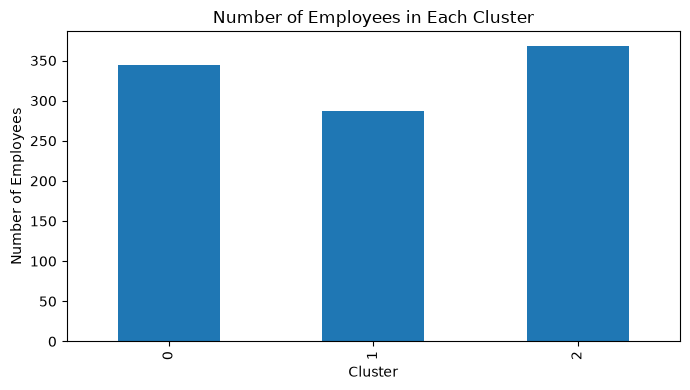

In [8]:
df["Cluster"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Number of Employees in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

In [9]:
attrition_by_cluster = pd.crosstab(
    df["Cluster"],
    df["Attrition"],
    normalize="index"
).round(3) * 100

print("Attrition Class Distribution by Cluster (%):")
print(attrition_by_cluster)

Attrition Class Distribution by Cluster (%):
Attrition     0     1
Cluster              
0          73.0  27.0
1          78.4  21.6
2          79.6  20.4


In [10]:
cluster_counts = df.groupby("Cluster").size()

class1_counts = df[df["Attrition"] == 1].groupby("Cluster").size()

risk_summary = pd.DataFrame({
    "Total_Employees": cluster_counts,
    "Class_1_Employees": class1_counts
}).fillna(0)

risk_summary["Class_1_Percentage"] = (
    risk_summary["Class_1_Employees"]
    / risk_summary["Total_Employees"] * 100
).round(2)

print(risk_summary)

         Total_Employees  Class_1_Employees  Class_1_Percentage
Cluster                                                        
0                    345                 93               26.96
1                    287                 62               21.60
2                    368                 75               20.38


In [11]:
if 2 <= k < len(X_scaled):
    score = silhouette_score(X_scaled, df["Cluster"])
    print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.192
